In [1]:
import sys; print(sys.executable)

/Users/seanli/Desktop/personal/rl-car-racing/.venv/bin/python


In [2]:
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path

ROOT = Path("/Users/seanli/Desktop/personal/rl-car-racing")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [11]:
from models import dataset
import numpy as np
import matplotlib.pyplot as plt

data = dataset.Episodes()

In [12]:
x, y = data[0]
print(x.shape)

(96, 96, 3)


In [13]:
print(np.mean(data.labels))

-0.020452302


In [14]:
def plot_kde(values, title=None, xlabel="value", ax=None, color="#2a78d6"):
    """Plot a Gaussian KDE of any numeric array (flattened). Returns the Axes."""
    x = np.asarray(values, dtype=np.float64).ravel()
    x = x[np.isfinite(x)]
    if x.size == 0:
        raise ValueError("plot_kde got no finite values")

    # Scott's rule bandwidth; fall back to a small width if all values are identical
    bw = 1.06 * x.std() * x.size ** (-1 / 5)
    if bw == 0:
        bw = max(abs(x[0]) * 0.01, 1e-3)

    grid = np.linspace(x.min() - 3 * bw, x.max() + 3 * bw, 512)
    density = np.zeros_like(grid)
    for chunk in np.array_split(x, max(1, x.size // 5000)):   # chunked to keep memory small
        density += np.exp(-0.5 * ((grid[:, None] - chunk[None, :]) / bw) ** 2).sum(axis=1)
    density /= x.size * bw * np.sqrt(2 * np.pi)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))
    ax.plot(grid, density, color=color, linewidth=2)
    ax.fill_between(grid, density, color=color, alpha=0.15, linewidth=0)
    ax.set_title(f"{title or 'Distribution'} (n={x.size:,})", loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("density")
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(length=0)
    ax.set_ylim(bottom=0)
    return ax

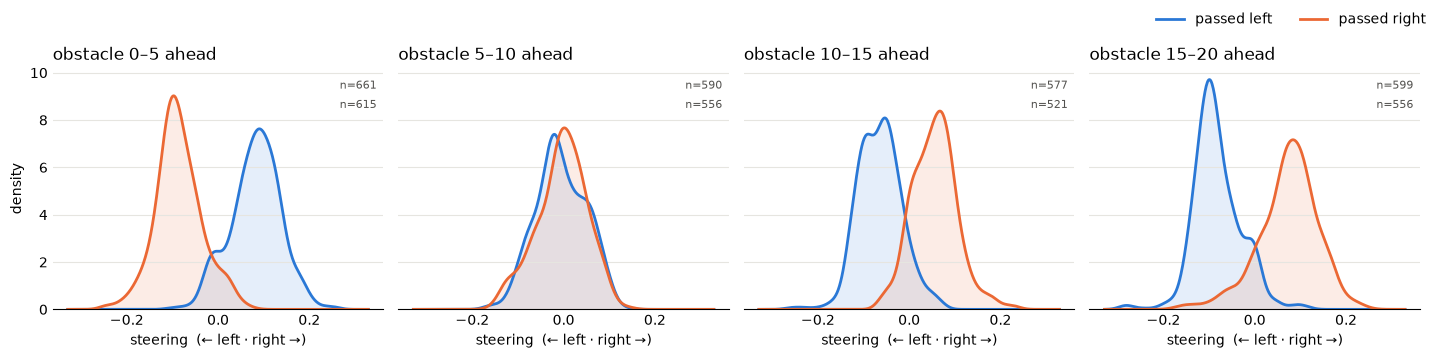

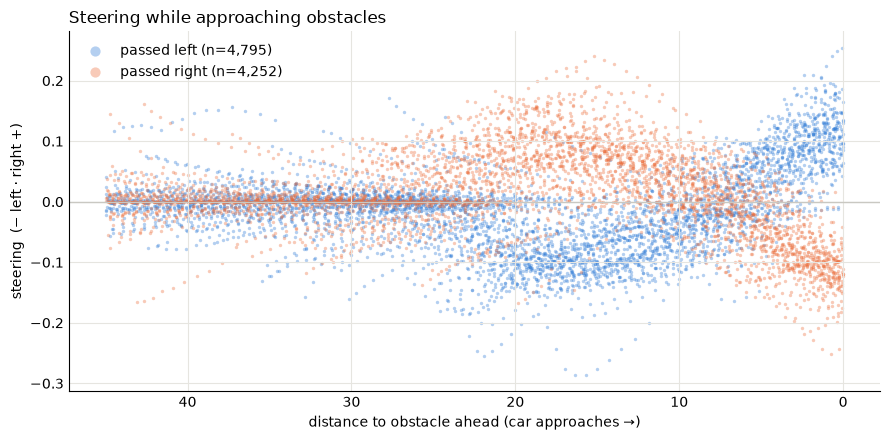

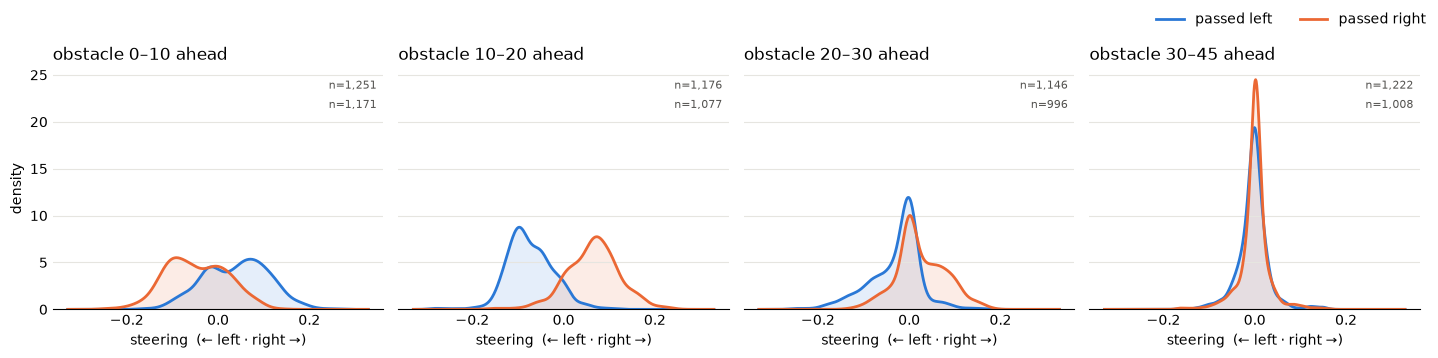

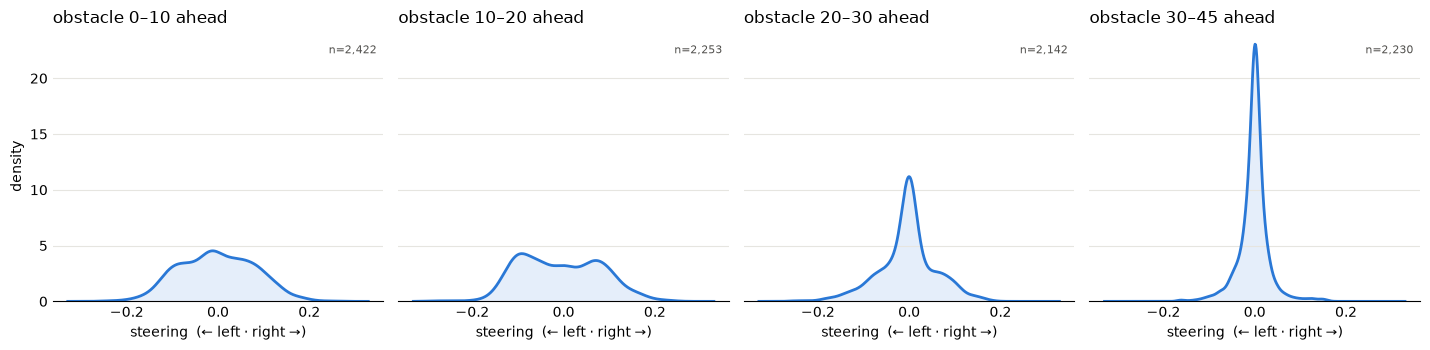

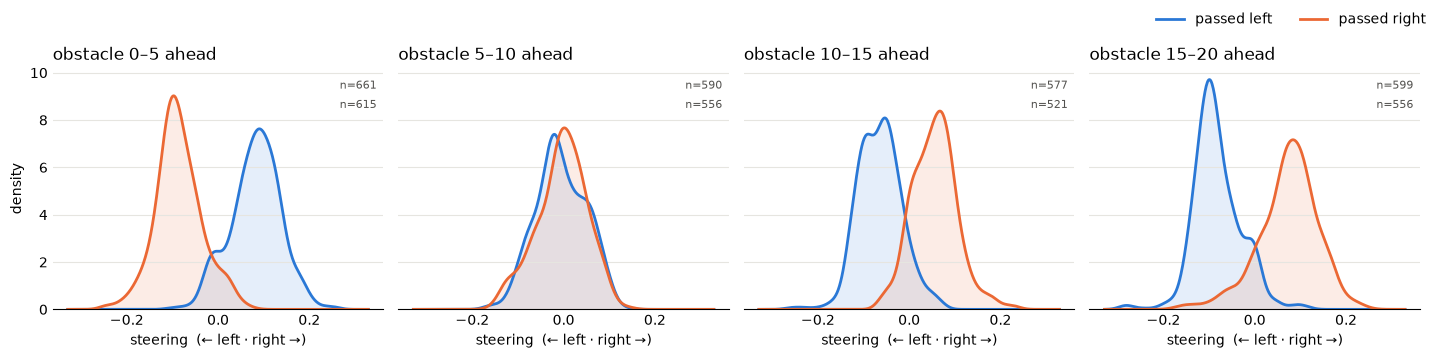

In [9]:
from exploration.obstacle_features import all_features, plot_steering_by_distance, plot_steering_vs_distance

feats = all_features()          # about 1 second; a dict of per-frame arrays

plot_steering_vs_distance(feats)                        # scatter: steering vs distance
plot_steering_by_distance(feats)                        # KDE per distance bin, split by side
plot_steering_by_distance(feats, split_by_side=False)   # the same bins as one combined curve each
plot_steering_by_distance(feats, bins=(0, 5, 10, 15, 20))  # choose your own distance bins